# Used Car Price Predictor (CarDekho)
Regression project: predict a used car's selling price (₹) from age, km driven, fuel, seller type, transmission, owner, brand and model.

**Run the cells top to bottom.** Cell 2 asks you to upload `CAR DETAILS FROM CAR DEKHO.csv`.

## 1. Imports

In [12]:
import os, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("plots", exist_ok=True)
os.makedirs("models", exist_ok=True)
RANDOM_STATE = 42
CURRENT_YEAR = datetime.datetime.now().year
print("Ready. Current year:", CURRENT_YEAR)

Ready. Current year: 2026


## 2. Upload and load the dataset

In [13]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")

print("Path to dataset files:", path)

df = pd.read_csv(path + "/CAR DETAILS FROM CAR DEKHO.csv")
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Path to dataset files: /kaggle/input/vehicle-dataset-from-cardekho
Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Inspect

In [14]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [15]:
df.dtypes


,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object


In [16]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Missing values:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate rows: 763


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [17]:
cat_cols = ["fuel", "seller_type", "transmission", "owner"]
for i in cat_cols:
    print(f"\n{i}:")
    print(df[i].value_counts())


fuel:
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

seller_type:
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

transmission:
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

owner:
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


## 4. Clean and feature engineering

In [18]:
cat_cols = ["fuel", "seller_type", "transmission", "owner"]

In [19]:
for i in cat_cols:
  df[i] = df[i].str.title()
  df[i] = df[i].replace('NaN', np.nan)

In [20]:
for i in ["fuel", "seller_type", "transmission", "owner"]:
  df[i] = df[i].fillna(df[i].mode()[0])

In [21]:
df = df.drop_duplicates().reset_index(drop=True)

# Car age instead of year
df["car_age"] = CURRENT_YEAR - df["year"]

# Brand = first word of the name (fix known multi-word / typo cases)
df["brand"] = df["name"].str.split().str[0]
df["brand"] = df["brand"].replace({"Land": "Land Rover", "OpelCorsa": "Opel"})
# Group rare brands (fewer than 10 cars) into "Other"
counts = df["brand"].value_counts()
df["brand"] = df["brand"].where(df["brand"].map(counts) >= 10, "Other")

# Model = first two words of the name (e.g. "Maruti Swift"); strong price signal
df["model"] = df["name"].str.split().str[:2].str.join(" ")
df.loc[df["brand"] == "Other", "model"] = "Other"

# Remove extreme outliers (above 99th percentile)
price_cap = df["selling_price"].quantile(0.99)
km_cap = df["km_driven"].quantile(0.99)
df = df[(df["selling_price"] <= price_cap) & (df["km_driven"] <= km_cap)].reset_index(drop=True)

df = df.drop(columns=["name", "year"])
print("Shape after cleaning:", df.shape)
print("Brands:", sorted(df["brand"].unique()))
print("Unique models:", df["model"].nunique())
df.head()

Shape after cleaning: (3506, 9)
Brands: ['Audi', 'BMW', 'Chevrolet', 'Datsun', 'Fiat', 'Ford', 'Honda', 'Hyundai', 'Mahindra', 'Maruti', 'Mercedes-Benz', 'Nissan', 'Other', 'Renault', 'Skoda', 'Tata', 'Toyota', 'Volkswagen']
Unique models: 161


,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,brand,model
0,60000,70000,Petrol,Individual,Manual,First Owner,19,Maruti,Maruti 800
1,135000,50000,Petrol,Individual,Manual,First Owner,19,Maruti,Maruti Wagon
2,600000,100000,Diesel,Individual,Manual,First Owner,14,Hyundai,Hyundai Verna
3,250000,46000,Petrol,Individual,Manual,First Owner,9,Datsun,Datsun RediGO
4,450000,141000,Diesel,Individual,Manual,Second Owner,12,Honda,Honda Amaze


## 5. EDA (plots are saved in `plots/`)

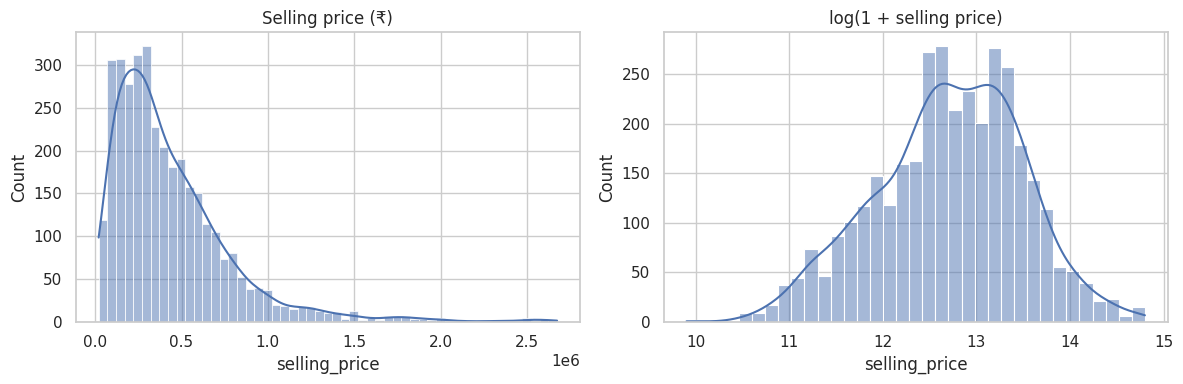

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["selling_price"], kde=True, ax=ax[0]); ax[0].set_title("Selling price (₹)")
sns.histplot(np.log1p(df["selling_price"]), kde=True, ax=ax[1]); ax[1].set_title("log(1 + selling price)")
plt.tight_layout(); plt.savefig("plots/01_price_distribution.png", dpi=150); plt.show()

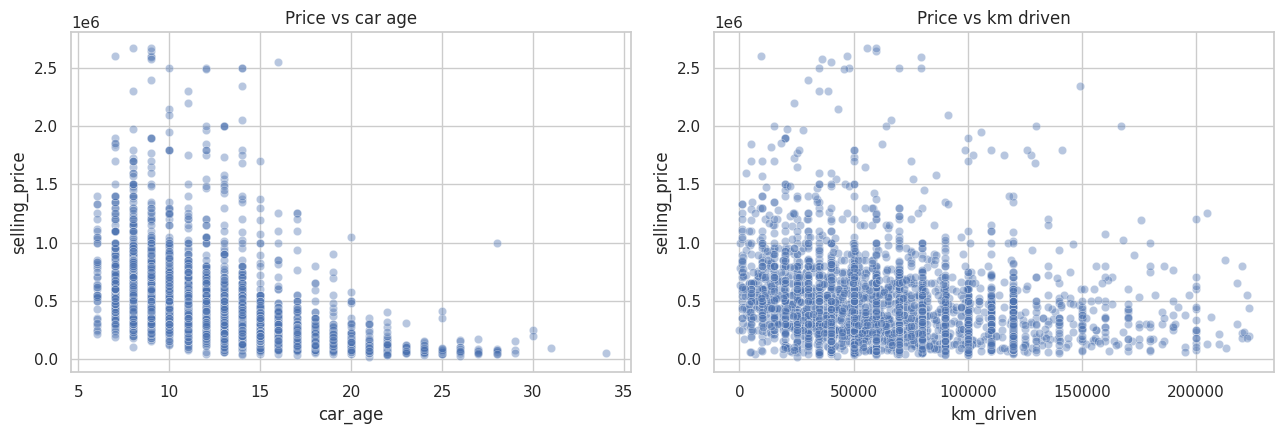

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="car_age", y="selling_price", alpha=0.4, ax=ax[0]); ax[0].set_title("Price vs car age")
sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.4, ax=ax[1]); ax[1].set_title("Price vs km driven")
plt.tight_layout(); plt.savefig("plots/02_price_vs_age_km.png", dpi=150); plt.show()

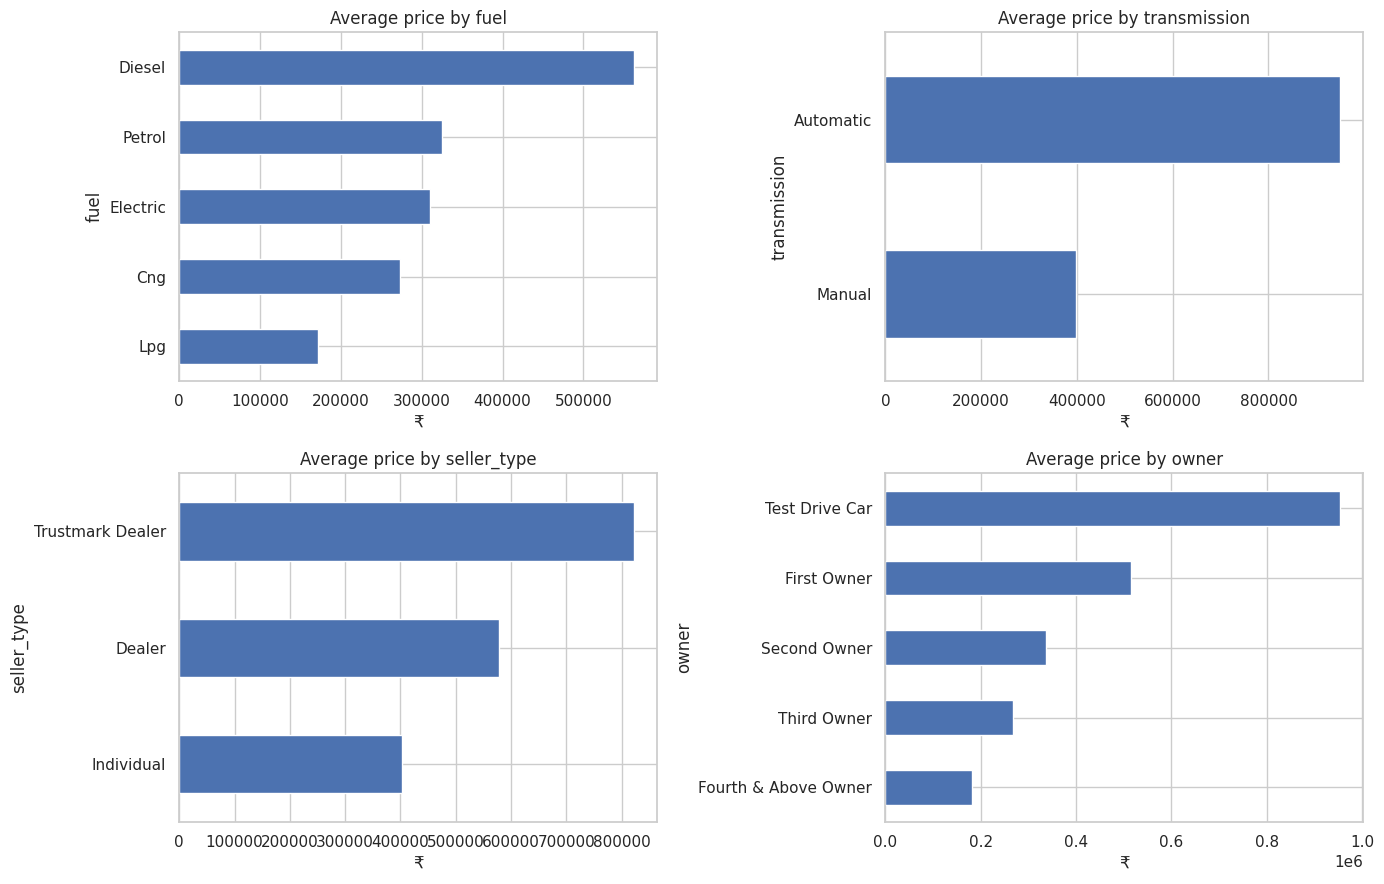

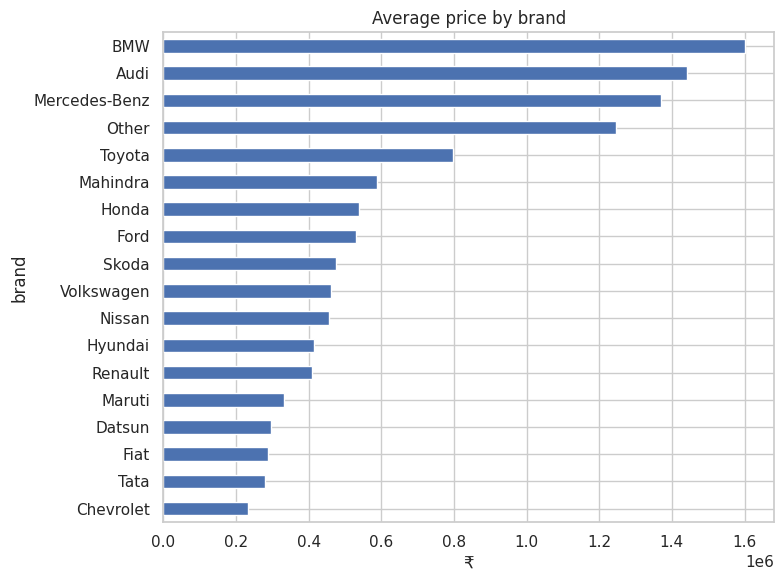

In [24]:
cats = ["fuel", "transmission", "seller_type", "owner"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for a, c in zip(axes.ravel(), cats):
    df.groupby(c)["selling_price"].mean().sort_values().plot(kind="barh", ax=a)
    a.set_title(f"Average price by {c}"); a.set_xlabel("₹")
plt.tight_layout(); plt.savefig("plots/03_price_by_category.png", dpi=150); plt.show()

plt.figure(figsize=(8, 6))
df.groupby("brand")["selling_price"].mean().sort_values().plot(kind="barh")
plt.title("Average price by brand"); plt.xlabel("₹")
plt.tight_layout(); plt.savefig("plots/04_price_by_brand.png", dpi=150); plt.show()

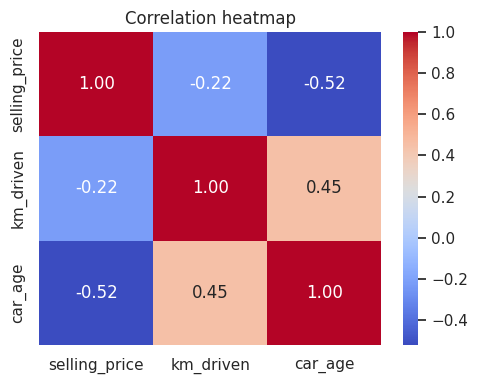

In [25]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[["selling_price", "km_driven", "car_age"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout(); plt.savefig("plots/05_correlation.png", dpi=150); plt.show()

## 6. Preprocessing + train/test split
The model predicts `log(1 + price)` internally and converts back to ₹ automatically (`TransformedTargetRegressor`).

In [26]:
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

cat_cols = ["fuel", "seller_type", "transmission", "owner", "brand", "model"]
num_cols = ["km_driven", "car_age"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

def make_model(regressor):
    pipe = Pipeline([("pre", preprocessor), ("model", regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

Train: (2804, 8) Test: (702, 8)


## 7. Train and compare models

In [27]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                            subsample=0.9, colsample_bytree=0.9, random_state=RANDOM_STATE),
}

rows, fitted = [], {}
for name, reg in models.items():
    m = make_model(reg).fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({
        "Model": name,
        "R2": r2_score(y_test, pred),
        "MAE (₹)": mean_absolute_error(y_test, pred),
        "RMSE (₹)": np.sqrt(mean_squared_error(y_test, pred)),
    })
    fitted[name] = m

results = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
results.round(3)

,Model,R2,MAE (₹),RMSE (₹)
0,Ridge,0.812,84659.548,163033.321
1,Linear Regression,0.802,85437.101,167130.922
2,XGBoost,0.752,95900.766,187115.162
3,Random Forest,0.714,103298.987,201146.715
4,Gradient Boosting,0.695,111118.350,207720.217


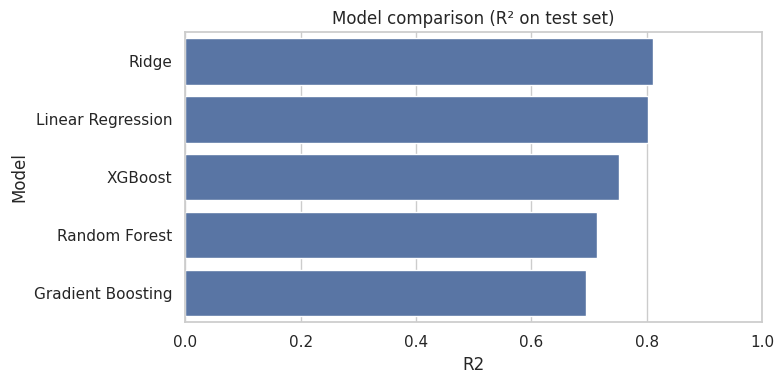

In [28]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results, x="R2", y="Model", orient="h")
plt.title("Model comparison (R² on test set)"); plt.xlim(0, 1)
plt.tight_layout(); plt.savefig("plots/06_model_comparison.png", dpi=150); plt.show()

## 8. Tune the best model (5-fold CV)

In [29]:
best_name = results.iloc[0]["Model"]   # best model from the comparison table
print("Tuning:", best_name)

param_grids = {
    "Linear Regression": {"regressor__model__fit_intercept": [True, False]},
    "Ridge": {"regressor__model__alpha": [0.1, 0.3, 1, 3, 10, 30]},
    "Random Forest": {
        "regressor__model__n_estimators": [200, 300, 500],
        "regressor__model__max_depth": [None, 10, 20],
        "regressor__model__min_samples_leaf": [1, 2, 4],
    },
    "Gradient Boosting": {
        "regressor__model__n_estimators": [200, 400, 600],
        "regressor__model__learning_rate": [0.03, 0.05, 0.1],
        "regressor__model__max_depth": [3, 4, 5],
    },
    "XGBoost": {
        "regressor__model__n_estimators": [300, 500, 800],
        "regressor__model__learning_rate": [0.03, 0.05, 0.1],
        "regressor__model__max_depth": [3, 4, 5, 6],
        "regressor__model__subsample": [0.8, 0.9, 1.0],
    },
}

search = RandomizedSearchCV(
    make_model(models[best_name]), param_grids[best_name],
    n_iter=min(15, int(np.prod([len(v) for v in param_grids[best_name].values()]))), cv=5, scoring="r2", random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Best CV R2:", round(search.best_score_, 4))

best_model = search.best_estimator_
pred = best_model.predict(X_test)
print(f"\nTest R2  : {r2_score(y_test, pred):.4f}")
print(f"Test MAE : ₹{mean_absolute_error(y_test, pred):,.0f}")
print(f"Test RMSE: ₹{np.sqrt(mean_squared_error(y_test, pred)):,.0f}")

Tuning: Ridge
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best params: {'regressor__model__alpha': 0.3}
Best CV R2: 0.8333

Test R2  : 0.8112
Test MAE : ₹84,309
Test RMSE: ₹163,349


## 9. Analyze results

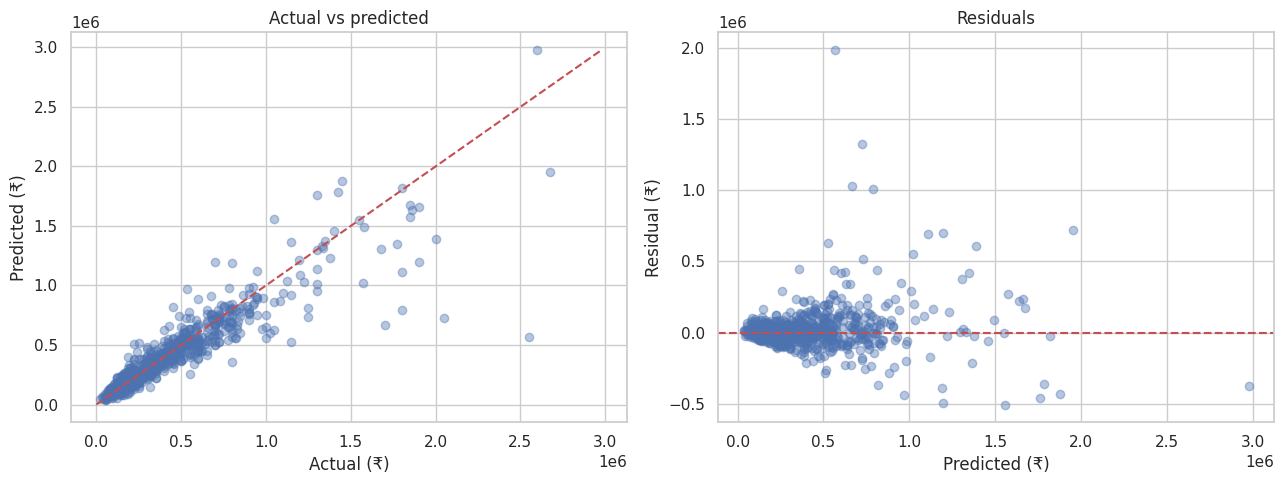

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, alpha=0.4)
lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual (₹)"); ax[0].set_ylabel("Predicted (₹)")
ax[0].set_title("Actual vs predicted")
resid = y_test - pred
ax[1].scatter(pred, resid, alpha=0.4); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted (₹)"); ax[1].set_ylabel("Residual (₹)"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.savefig("plots/07_actual_vs_predicted.png", dpi=150); plt.show()

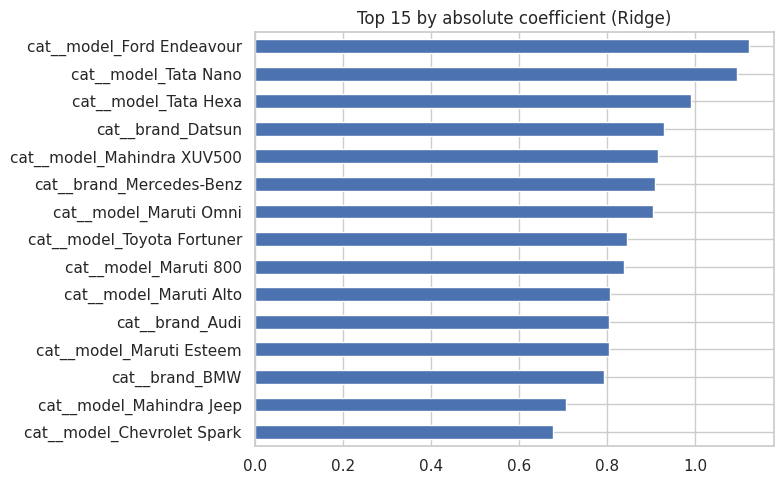

In [31]:
inner = best_model.regressor_
names = inner.named_steps["pre"].get_feature_names_out()
est = inner.named_steps["model"]
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=names)
    label = "feature importance"
else:  # linear models: size of the coefficient (features are on a comparable scale after encoding/scaling)
    imp = pd.Series(np.abs(est.coef_), index=names)
    label = "absolute coefficient"
imp = imp.sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
imp[::-1].plot(kind="barh"); plt.title(f"Top 15 by {label} ({best_name})")
plt.tight_layout(); plt.savefig("plots/08_feature_importance.png", dpi=150); plt.show()

## 10. Save the model

In [32]:
bundle = {
    "model": best_model,
    "brands": sorted(df["brand"].unique().tolist()),
    "models_by_brand": {b: sorted(g["model"].unique().tolist()) for b, g in df.groupby("brand")},
    "fuels": sorted(df["fuel"].unique().tolist()),
    "seller_types": sorted(df["seller_type"].unique().tolist()),
    "transmissions": sorted(df["transmission"].unique().tolist()),
    "owners": sorted(df["owner"].unique().tolist()),
    "current_year": CURRENT_YEAR,
}
joblib.dump(bundle, "models/car_price_model.pkl")
print("Saved models/car_price_model.pkl")

try:
    from google.colab import files
    files.download("models/car_price_model.pkl")
except ImportError:
    pass

Saved models/car_price_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Predict a price

In [33]:
def predict_price(brand, model, year, km_driven, fuel, seller_type, transmission, owner):
    row = pd.DataFrame([{
        "km_driven": km_driven,
        "fuel": fuel,
        "seller_type": seller_type,
        "transmission": transmission,
        "owner": owner,
        "car_age": CURRENT_YEAR - year,
        "brand": brand,
        "model": model,
    }])[X.columns]
    return float(best_model.predict(row)[0])

price = predict_price("Maruti", "Maruti Swift", 2015, 50000, "Petrol", "Individual", "Manual", "First Owner")
print(f"Estimated price: ₹{price:,.0f}")

Estimated price: ₹409,003


### Interactive predictor

In [34]:
import ipywidgets as widgets
from IPython.display import display

w_brand = widgets.Dropdown(options=bundle["brands"], description="Brand")
w_model = widgets.Dropdown(options=bundle["models_by_brand"][w_brand.value], description="Model")
def on_brand(change):
    w_model.options = bundle["models_by_brand"][change["new"]]
w_brand.observe(on_brand, names="value")
w_year  = widgets.IntSlider(value=2015, min=1995, max=CURRENT_YEAR, description="Year")
w_km    = widgets.IntText(value=50000, description="Km driven")
w_fuel  = widgets.Dropdown(options=bundle["fuels"], description="Fuel")
w_seller = widgets.Dropdown(options=bundle["seller_types"], description="Seller")
w_trans = widgets.Dropdown(options=bundle["transmissions"], description="Gearbox")
w_owner = widgets.Dropdown(options=bundle["owners"], description="Owner")
btn = widgets.Button(description="Predict price", button_style="success")
out = widgets.Output()

def on_click(_):
    with out:
        out.clear_output()
        p = predict_price(w_brand.value, w_model.value, w_year.value, w_km.value, w_fuel.value,
                          w_seller.value, w_trans.value, w_owner.value)
        print(f"Estimated selling price: ₹{p:,.0f}")

btn.on_click(on_click)
display(w_brand, w_model, w_year, w_km, w_fuel, w_seller, w_trans, w_owner, btn, out)

Dropdown(description='Brand', options=('Audi', 'BMW', 'Chevrolet', 'Datsun', 'Fiat', 'Ford', 'Honda', 'Hyundai…

Dropdown(description='Model', options=('Audi A4', 'Audi A6', 'Audi A8', 'Audi Q3', 'Audi Q5', 'Audi Q7'), valu…

IntSlider(value=2015, description='Year', max=2026, min=1995)

IntText(value=50000, description='Km driven')

Dropdown(description='Fuel', options=('Cng', 'Diesel', 'Electric', 'Lpg', 'Petrol'), value='Cng')

Dropdown(description='Seller', options=('Dealer', 'Individual', 'Trustmark Dealer'), value='Dealer')

Dropdown(description='Gearbox', options=('Automatic', 'Manual'), value='Automatic')

Dropdown(description='Owner', options=('First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car'…

Button(button_style='success', description='Predict price', style=ButtonStyle())

Output()